In [10]:
#format the book
import book_format
book_format.set_style()

# 1D Linear Kalman filter 


Now that we understand the discrete Bayes filter and Gaussians we are prepared to implement a Kalman filter. We will do this exactly as we did the discrete Bayes filter - rather than starting with equations we will develop the code step by step based on reasoning about the problem.

"One dimensional" means that the filter only tracks one state variable, such as position on the x-axis. In subsequent chapters we will learn a more general multidimensional form of the filter that can track many state variables simultaneously, such as position, velocity, and acceleration.

So why not just jump into the multidimensional form of the filter? To be honest, the math is difficult, and the intuitive approach to developing the filter starts to break down. This math obscures the rather simple principles that allow the Kalman filter to work.

So, in this chapter we learn how to use Gaussians to implement a Bayesian filter. That's all the Kalman filter is - a Bayesian filter that uses Gaussians. In the next chapter we will switch to a multidimensional form and the full power of the Kalman filter will be unleashed!

## Problem Description

As in the **Discrete Bayes Filter** chapter we will be tracking a moving object in a long hallway at work. Assume that in our latest hackathon someone created an RFID tracker that provides a reasonably accurate position of the dog. The sensor returns the distance of the dog from the left end of the hallway in meters. So, 23.4 would mean the dog is 23.4 meters from the left end of the hallway.

The sensor is not perfect. A reading of 23.4 could correspond to the dog being at 23.7, or 23.0. However, it is very unlikely to correspond to a position of 47.6. Testing during the hackathon confirmed this result - the sensor is 'reasonably' accurate, and while it had errors, the errors are small. Furthermore, the errors seemed to be evenly distributed on both sides of the true position; a position of 23 m would equally likely be measured as 22.9 or 23.1. Perhaps we can model this with a Gaussian.

We predict that the dog is moving. This prediction is not perfect. Sometimes our prediction will overshoot, sometimes it will undershoot. We are more likely to undershoot or overshoot by a little than a lot. Perhaps we can also model this with a Gaussian.

## Beliefs as Gaussians

We can express our belief in the dog's position with a Gaussian. Say we believe that our dog is at 10 meters, and the variance in that belief is 1 m$^2$, or $\mathcal{N}(10,\, 1)$. A plot of the pdf follows:

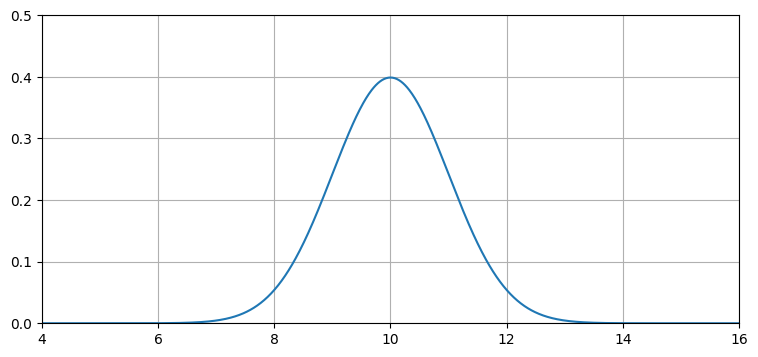

In [14]:
import filterpy.stats as stats
stats.plot_gaussian_pdf(mean=10., variance=1., 
                        xlim=(4, 16), ylim=(0, .5));

This plot depicts our uncertainty about the dog's position. It represents a fairly inexact belief. While we believe that it is most likely that the dog is at 10 m, any position from 9 m to 11 m or so are quite likely as well. Assume the dog is standing still, and we query the sensor again. This time it returns 10.2 m. Can we use this additional information to improve our estimate?

Intuition suggests we can. Consider: if we read the sensor 500 times and each time it returned a value between 8 and 12, all centered around 10, we should be very confident that the dog is near 10. Of course, a different interpretation is possible. Perhaps our dog was randomly wandering back and forth in a way that exactly emulated random draws from a normal distribution. But that seems extremely unlikely - I've never seen a dog do that. Let's look at 500 draws from $\mathcal N(10, 1)$:

Mean of readings is 10.026


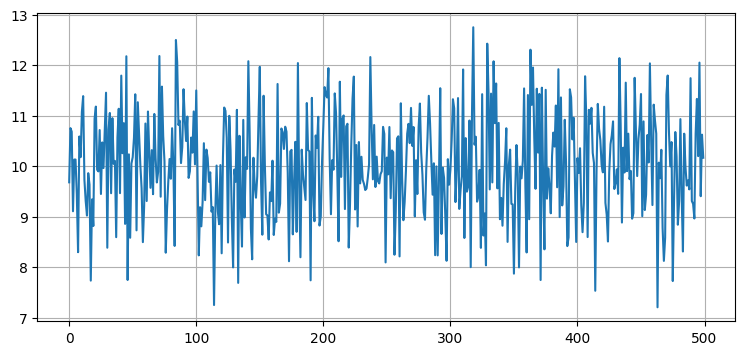

In [15]:
import numpy as np
from numpy.random import randn
import matplotlib.pyplot as plt

xs = range(500)
ys = randn(500)*1. + 10.
plt.plot(xs, ys)
print(f'Mean of readings is {np.mean(ys):.3f}')

Eyeballing this confirms our intuition - no dog moves like this. However, noisy sensor data certainly looks this way.  The computed mean of the readings is almost exactly 10. Assuming the dog is standing still, we say the dog is at position 10 with a variance of 1.

## Tracking with Gaussian Probabilities

The discrete Bayes filter used a histogram of probabilities to track the dog. Each bin in the histogram represents a position, and the value is the probability of the dog being in that position.

Tracking was performed with a cycle of predictions and updates. We used the equations 

$\begin{aligned} 
\bar {\mathbf x} &= \mathbf x \ast f_{\mathbf x}(\bullet)\, \, &\text{Predict} \\
\mathbf x &= \mathcal L \cdot \bar{\mathbf x}\, \, &\text{Update}
\end{aligned}$

to compute the new probability distributions. Recall that $\bar{\mathbf x}$ is the **prior**, $\mathcal L$ is the **likelihood** of a measurement given the prior $\bar{\mathbf x}$, $f_{\mathbf x}(\bullet)$ is the **process model**, and $\ast$ denotes **convolution**. $\mathbf x$ is bold to denote that it is a histogram of numbers, or a vector.

This method works, but led to histograms that implied the dog could be in multiple places at once. Also, the computations are very slow for large problems.

Can we replace $\mathbf x$, the histogram, with a Gaussian $\mathcal N(x, \sigma^2)$? Absolutely! We've learned how to express belief as a Gaussian. A Gaussian, which is a single number pair $\mathcal N(\mu, \sigma^2),$ can replace an entire histogram of probabilities:

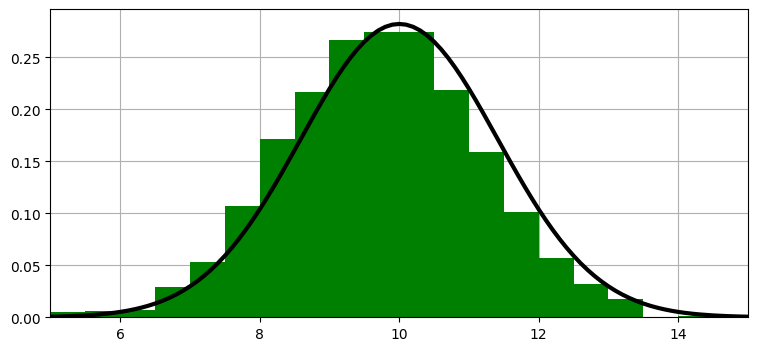

In [16]:
import kf_book.kf_internal as kf_internal
kf_internal.gaussian_vs_histogram()

I hope you see the power of this. We can replace hundreds to thousands of numbers with a single pair of numbers: $x = \mathcal N(\mu, \sigma^2)$. 

The tails of the Gaussian extend to infinity on both sides, so it incorporates arbitrarily many bars in the histogram. If this represents our belief in the position of the dog in the hallway, this one Gaussian covers the entire hallway (and the entire universe on that axis). We think that it is likely the dog is at 10, but he could be at 8, 14, or, with infinitesimally small probability, at 10$^{80}$. 

In this chapter we replace histograms with Gaussians:

$\begin{array}{l|l|c}
\text{discrete Bayes} & \text{Gaussian} & \text{Step}\\
\hline
\bar {\mathbf x} = \mathbf x \ast f(\mathbf x) & \bar {x}_{\mathcal{N}} = x_{\mathcal{N}} \, \oplus \, f_{x_{\mathcal{N}}}(\bullet)  & \text{Predict} \\
\mathbf x = \| \mathcal L \bar{\mathbf x} \| & x_{\mathcal{N}} = L \, \otimes \, \bar{x}_{\mathcal{N}} & \text{Update} 
\end{array}$

where $\oplus$ and $\otimes$ is meant to express some unknown operator on Gaussians. I won't do it in the rest of the book, but the subscript indicates that $x_{\mathcal{N}}$ is a Gaussian. 

The discrete Bayes filter used convolution for the prediction. We showed that it used the *total probabability theorem*, computed as a sum, so maybe we can add the Gaussians. It used multiplications to incorporate the measurement into the prior, so maybe we can multiply the Gaussians. Could it be this easy:

$\begin{aligned} 
\bar x &\stackrel{?}{=} x + f_x(\bullet) \\
x &\stackrel{?}{=} \mathcal L \cdot \bar x
\end{aligned}$

This will only work if the sum and product of two Gaussians is another Gaussian. Otherwise after the first epoch $x$ would not be Gaussian, and this scheme falls apart.

## Predictions with Gaussians

We use Newton's equation of motion to compute current position based on the current velocity and previous position:

$ \begin{aligned}\bar{x}_k &= x_{k-1} + v_k \Delta t \\
 &= x_{k-1} + f_x\end{aligned}$

I've dropped the notation $f_x(\bullet)$ in favor of $f_x$ to keep the equations uncluttered. 

If the dog is at 10 m, his velocity is 15 m/s, and the epoch is 2 seconds long, we have

$ \begin{aligned} f_x &= v\Delta t = 15\cdot 2\\
\bar{x}_k &= 10 + (15\cdot 2) = 40 \end{aligned}$

We are uncertain about his current position and velocity, so this will not do. We need to express the uncertainty with a Gaussian.

Position is easy. We define $x$ as a Gaussian. If we think the dog is at 10 m, and the standard deviation of our uncertainty is 0.2 m, we get $x=\mathcal N(10, 0.2^2)$.

What about our uncertainty in his movement? We define $f_x$ as a Gaussian. If the dog's velocity is 15 m/s, the epoch is 1 second, and the standard deviation of our uncertainty is 0.7 m/s, we get $f_x = \mathcal N (15, 0.7^2)$.

The equation for the prior is 

$\bar x = x + f_x$

**What is the sum of two Gaussians?** 

To find the density function of the sum of two Gaussian random variables we sum the density functions of each. They are nonlinear, continuous functions, so we need to compute the sum with an integral. 

If the random variables $p$ and $z$ (e.g. prior and measurement) are independent we can compute this with

$p(x) = \int\limits_{-\infty}^\infty f_p(x-z)f_z(z)\, dx$

This is the equation for a **convolution**. Now we just do some math:


$p(x) = \int\limits_{-\infty}^\infty f_2(x-x_1)f_1(x_1)\, dx$

$=  \int\limits_{-\infty}^\infty 
\frac{1}{\sqrt{2\pi}\sigma_z}\exp\left[-\frac{(x - z - \mu_z)^2}{2\sigma^2_z}\right]
\frac{1}{\sqrt{2\pi}\sigma_p}\exp\left[-\frac{(x - \mu_p)^2}{2\sigma^2_p}\right] \, dx$

$=  \int\limits_{-\infty}^\infty
\frac{1}{\sqrt{2\pi}\sqrt{\sigma_p^2 + \sigma_z^2}} \exp\left[ -\frac{(x - (\mu_p + \mu_z)))^2}{2(\sigma_z^2+\sigma_p^2)}\right]
\frac{1}{\sqrt{2\pi}\frac{\sigma_p\sigma_z}{\sqrt{\sigma_p^2 + \sigma_z^2}}} \exp\left[ -\frac{(x - \frac{\sigma_p^2(x-\mu_z) + \sigma_z^2\mu_p}{}))^2}{2\left(\frac{\sigma_p\sigma_x}{\sqrt{\sigma_z^2+\sigma_p^2}}\right)^2}\right] \, dx$

$= \frac{1}{\sqrt{2\pi}\sqrt{\sigma_p^2 + \sigma_z^2}} \exp\left[ -\frac{(x - (\mu_p + \mu_z)))^2}{2(\sigma_z^2+\sigma_p^2)}\right] \int\limits_{-\infty}^\infty
\frac{1}{\sqrt{2\pi}\frac{\sigma_p\sigma_z}{\sqrt{\sigma_p^2 + \sigma_z^2}}} \exp\left[ -\frac{(x - \frac{\sigma_p^2(x-\mu_z) + \sigma_z^2\mu_p}{}))^2}{2\left(\frac{\sigma_p\sigma_x}{\sqrt{\sigma_z^2+\sigma_p^2}}\right)^2}\right] \, dx$

The expression inside the integral is a normal distribution. The sum of a normal distribution is one, hence the integral is one. This gives us

$p(x) = \frac{1}{\sqrt{2\pi}\sqrt{\sigma_p^2 + \sigma_z^2}} \exp\left[ -\frac{(x - (\mu_p + \mu_z)))^2}{2(\sigma_z^2+\sigma_p^2)}\right]$

This is in the form of a normal, where

$\begin{gathered}\mu_x = \mu_p + \mu_z \\
\sigma_x^2 = \sigma_z^2+\sigma_p^2 \end{gathered}$

This is in the form of a normal, where

$\begin{gathered}\mu_x = \mu_p + \mu_z \\
\sigma_x^2 = \sigma_z^2+\sigma_p^2 \end{gathered}$

This is fantastic news; **the sum of two Gaussians is another Gaussian**! 

We can transform the previous two variables $z$ and $p$ to our predicted variables $x$ anf $f_x$   

$\begin{gathered}
x=\mathcal N(10, 0.2^2)= N(\mu_x, \sigma_x^2)\\
f_x = \mathcal N (15, 0.7^2)=  N(\mu_{f_x}, \sigma_{f_x}^2)
\end{gathered}$

If we add these we get:

$\begin{aligned}\bar x &= \mu_x + \mu_{f_x} = 10 + 15 = 25 \\
\bar\sigma^2 &= \sigma_x^2 + \sigma_{f_x}^2 = 0.2^2 + 0.7^2 = 0.53\end{aligned}$

It makes sense that the predicted position is the previous position plus the movement. What about the variance? It is harder to form an intuition about this. However, recall that with the `predict()` function for the discrete Bayes filter we always lost information. We don't really know where the dog is moving, so the confidence should get smaller (variance gets larger). $\sigma_{f_x}^2$ is the amount of uncertainty added to the system due to the imperfect prediction about the movement, and so we would add that to the existing uncertainty. 
 

## Updates with Gaussians

The discrete Bayes filter encodes our belief about the position of our dog in a histogram of probabilities. The distribution is discrete and multimodal. It can express strong belief that the dog is in two positions at once, and the positions are discrete.

We are proposing that we replace the histogram with a Gaussian. The discrete Bayes filter used this code to compute the posterior:


```python
def update(likelihood, prior):
    posterior = likelihood * prior
    return normalize(posterior)
```

which is an implementation of the equation:

$x = \| \mathcal L\bar x \|$

We've just shown that we can represent the prior with a Gaussian. What about the likelihood? The likelihood is the probability of the measurement given the current state. We've learned how to represent measurements as Gaussians. For example, maybe our sensor states that the dog is at 23 m, with a standard deviation of 0.4 meters. Our measurement, expressed as a likelihood, is $z = \mathcal N (23, 0.16)$.

Both the likelihood and prior are modeled with Gaussians. Can we multiply Gaussians? Is the product of two Gaussians another Gaussian?


You can find this result by multiplying the equation for two Gaussians together and combining terms. The algebra gets messy. We will derive it using Bayes theorem. We can state the problem as: let the prior be $N(\bar\mu, \bar\sigma^2)$, and measurement be $z \propto N(z, \sigma_z^2)$. 

What is the posterior of x given the measurement z?

Write the posterior as $p(x \mid z)$. Now we can use Bayes Theorem to state

$p(x \mid z) = \frac{p(z \mid x)p(x)}{p(z)}$

$p(z)$ is a normalizing constant, so we can create a proportinality

$p(x \mid z) \propto p(z|x)p(x)$

Now we subtitute in the equations for the Gaussians, which are

$p(z \mid x) = \frac{1}{\sqrt{2\pi\sigma_z^2}}\exp \Big[-\frac{(z-x)^2}{2\sigma_z^2}\Big]$

$p(x) = \frac{1}{\sqrt{2\pi\bar\sigma^2}}\exp \Big[-\frac{(x-\bar\mu)^2}{2\bar\sigma^2}\Big]$

We can drop the leading terms, as they are constants, giving us

$\begin{aligned}
p(x \mid z) &\propto \exp \Big[-\frac{(z-x)^2}{2\sigma_z^2}\Big]\exp \Big[-\frac{(x-\bar\mu)^2}{2\bar\sigma^2}\Big]\\
&\propto \exp \Big[-\frac{(z-x)^2}{2\sigma_z^2}-\frac{(x-\bar\mu)^2}{2\bar\sigma^2}\Big] \\
&\propto \exp \Big[-\frac{1}{2\sigma_z^2\bar\sigma^2}[\bar\sigma^2(z-x)^2+\sigma_z^2(x-\bar\mu)^2]\Big]
\end{aligned}$

Now we multiply out the squared terms and group in terms of the posterior $x$.

$\begin{aligned}
p(x \mid z) &\propto \exp \Big[-\frac{1}{2\sigma_z^2\bar\sigma^2}[\bar\sigma^2(z^2 -2xz + x^2) + \sigma_z^2(x^2 - 2x\bar\mu+\bar\mu^2)]\Big ] \\
&\propto \exp \Big[-\frac{1}{2\sigma_z^2\bar\sigma^2}[x^2(\bar\sigma^2+\sigma_z^2)-2x(\sigma_z^2\bar\mu + \bar\sigma^2z) + (\bar\sigma^2z^2+\sigma_z^2\bar\mu^2)]\Big ]
\end{aligned}$

The last parentheses do not contain the posterior $x$, so it can be treated as a constant and discarded.

$p(x \mid z) \propto \exp \Big[-\frac{1}{2}\frac{x^2(\bar\sigma^2+\sigma_z^2)-2x(\sigma_z^2\bar\mu + \bar\sigma^2z)}{\sigma_z^2\bar\sigma^2}\Big ]
$

Divide numerator and denominator by $\bar\sigma^2+\sigma_z^2$ to get

$p(x \mid z) \propto \exp \Big[-\frac{1}{2}\frac{x^2-2x(\frac{\sigma_z^2\bar\mu + \bar\sigma^2z}{\bar\sigma^2+\sigma_z^2})}{\frac{\sigma_z^2\bar\sigma^2}{\bar\sigma^2+\sigma_z^2}}\Big ]
$

Proportionality allows us create or delete constants at will, so we can factor this into

$p(x \mid z) \propto \exp \Big[-\frac{1}{2}\frac{(x-\frac{\sigma_z^2\bar\mu + \bar\sigma^2z}{\bar\sigma^2+\sigma_z^2})^2}{\frac{\sigma_z^2\bar\sigma^2}{\bar\sigma^2+\sigma_z^2}}\Big ]
$

A Gaussian is

$N(\mu,\, \sigma^2) \propto \exp\Big [-\frac{1}{2}\frac{(x - \mu)^2}{\sigma^2}\Big ]$

So we can see that $p(x \mid z)$ has a mean of

$\mu_\mathtt{posterior} = \frac{\sigma_z^2\bar\mu + \bar\sigma^2z}{\bar\sigma^2+\sigma_z^2}$

and a variance of
$
\sigma_\mathtt{posterior} = \frac{\sigma_z^2\bar\sigma^2}{\bar\sigma^2+\sigma_z^2}
$

I've dropped the constants, and so the result is not a normal, but proportional to one. Bayes theorem normalizes with the $p(z)$ divisor, ensuring that the result is normal. We normalize in the update step of our filters, ensuring the filter estimate is Gaussian.

$\mathcal N_1 = \| \mathcal N_2\cdot \mathcal N_3\|$

We proved that the product of two Gaussians is proportional to another Gausian. 

$\begin{aligned}
\mu &= \frac{\sigma_1^2 \mu_2 + \sigma_2^2 \mu_1} {\sigma_1^2 + \sigma_2^2}, \\
\sigma^2 &= \frac{\sigma_1^2\sigma_2^2}{\sigma_1^2+\sigma_2^2}
\end{aligned}$

We can immediately infer several things. If we normalize the result, the product is another Gaussian. If one Gaussian is the likelihood, and the second is the prior, then the mean is a scaled sum of the prior and the measurement. The variance is a combination of the variances of the prior and measurement. Finally, the variances are completely unaffected by the values of the mean!

We put this in Bayesian terms like so:

$\begin{aligned}
\mathcal N(\mu, \sigma^2) &= \| prior \cdot likelihood \|\\
&= \| \mathcal{N}(\bar\mu, \bar\sigma^2)\cdot \mathcal{N}(\mu_z, \sigma_z^2) \|\\
&= \mathcal N(\frac{\bar\sigma^2 \mu_z + \sigma_z^2 \bar\mu}{\bar\sigma^2 + \sigma_z^2},\frac{\bar\sigma^2\sigma_z^2}{\bar\sigma^2 + \sigma_z^2})
\end{aligned}$

 ### Interactive Example: multiplication of Gaussians

This interactive code provides sliders to alter the mean and variance of two Gaussians that are being multiplied together. As you move the sliders the plot is redrawn. 

In [21]:
import filterpy.stats as stats
from ipywidgets import interact
from collections import namedtuple
import matplotlib.pyplot as plt
import numpy as np 

gaussian = namedtuple('Gaussian', ['mean', 'var'])
gaussian.__repr__ = lambda s: '𝒩(μ={:.3f}, 𝜎²={:.3f})'.format(s[0], s[1])

def interactive_gaussian(m1, m2, v1, v2):
    g1 = gaussian(m1, v1)
    g2 = gaussian(m2, v2)
    plot_products(g1, g2)
    
def plot_products(g1, g2): 
    plt.figure(figsize=(16,8))
    product = gaussian_multiply(g1, g2)

    xs = np.arange(5, 15, 0.1)
    ys = [stats.gaussian(x, g1.mean, g1.var) for x in xs]
    plt.plot(xs, ys, label='$\mathcal{N}$'+'$({},{})$'.format(g1.mean, g1.var))

    ys = [stats.gaussian(x, g2.mean, g2.var) for x in xs]
    plt.plot(xs, ys, label='$\mathcal{N}$'+'$({},{})$'.format(g2.mean, g2.var))

    ys = [stats.gaussian(x, product.mean, product.var) for x in xs]
    plt.plot(xs, ys, label='product', ls='--')
    plt.legend();

def gaussian_multiply(g1, g2):
    mean = (g1.var * g2.mean + g2.var * g1.mean) / (g1.var + g2.var)
    variance = (g1.var * g2.var) / (g1.var + g2.var)
    return gaussian(mean, variance)


interact(interactive_gaussian,
         m1=(5, 10., .5), m2=(10, 15, .5), 
         v1=(.1, 2, .1), v2=(.1, 2, .1));

interactive(children=(FloatSlider(value=7.5, description='m1', max=10.0, min=5.0, step=0.5), FloatSlider(value…

## Kalman Gain

We see that the filter works. Now let's go back to the math to understand what is happening. The posterior $x$ is computed as the likelihood times the prior ($\mathcal L \bar x$), where both are Gaussians.

Therefore the mean of the posterior is given by:

$
\mu=\frac{\bar\sigma^2\, \mu_z + \sigma_z^2 \, \bar\mu} {\bar\sigma^2 + \sigma_z^2}
$

I use the subscript $z$ to denote the measurement. We can rewrite this as:

$\mu = \left( \frac{\bar\sigma^2}{\bar\sigma^2 + \sigma_z^2}\right) \mu_z + \left(\frac{\sigma_z^2}{\bar\sigma^2 + \sigma_z^2}\right)\bar\mu$

In this form it is easy to see that we are scaling the measurement and the prior by weights: 

$\mu = W_1 \mu_z + W_2 \bar\mu$


The weights sum to one because the denominator is a normalization term. We introduce a new term, $K=W_1$, giving us:

$\begin{aligned}
\mu &= K \mu_z + (1-K) \bar\mu\\
&= \bar\mu + K(\mu_z - \bar\mu)
\end{aligned}$

where

$K = \frac {\bar\sigma^2}{\bar\sigma^2 + \sigma_z^2}$

$K$ is the *Kalman gain*. It's the crux of the Kalman filter. It is a scaling term that chooses a value partway between $\mu_z$ and $\bar\mu$.

Let's work a few examples. If the measurement is nine times more accurate than the prior, then $\bar\sigma^2 = 9\sigma_z^2$, and

$\begin{aligned}
\mu&=\frac{9 \sigma_z^2 \mu_z + \sigma_z^2\, \bar\mu} {9 \sigma_z^2 + \sigma_\mathtt{z}^2} \\
&= \left(\frac{9}{10}\right) \mu_z + \left(\frac{1}{10}\right) \bar\mu
\end{aligned}
$


Hence $K = \frac 9 {10}$, and to form the posterior we take nine tenths of the measurement and one tenth of the prior. 

If the measurement and prior are equally accurate, then $\bar\sigma^2 = \sigma_z^2$ and

$\begin{gathered}
\mu=\frac{\sigma_z^2\,  (\bar\mu + \mu_z)}{2\sigma_\mathtt{z}^2} \\
= \left(\frac{1}{2}\right)\bar\mu + \left(\frac{1}{2}\right)\mu_z
\end{gathered}$

which is the average of the two means. It makes intuitive sense to take the average of two equally accurate values.

We can also express the variance in terms of the Kalman gain:

$\begin{aligned}
\sigma^2 &= \frac{\bar\sigma^2 \sigma_z^2 } {\bar\sigma^2 + \sigma_z^2} \\
&= K\sigma_z^2 \\
&= (1-K)\bar\sigma^2 
\end{aligned}$

We can understand this by looking at this chart:

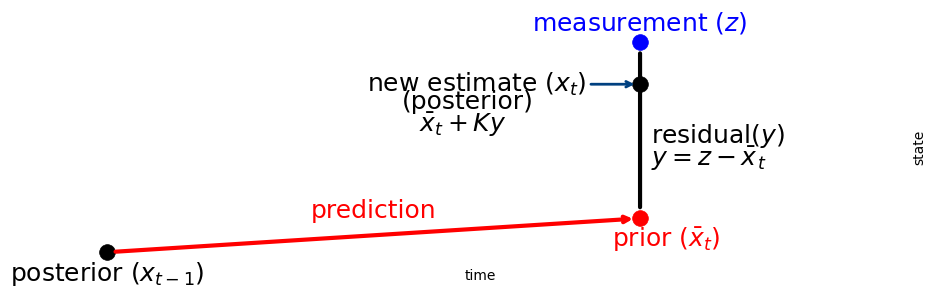

In [17]:
import kf_book.book_plots as book_plots
book_plots.show_residual_chart()

The Kalman gain $K$ is a scale factor that chooses a value along the residual. This leads to an alternative but equivalent implementation for `update()` and `predict()`:

In [18]:
def update(prior, measurement):
    x, P = prior        # mean and variance of prior
    z, R = measurement  # mean and variance of measurement
    
    y = z - x        # residual
    K = P / (P + R)  # Kalman gain

    x = x + K*y      # posterior
    P = (1 - K) * P  # posterior variance
    return gaussian(x, P)

def predict(posterior, movement):
    x, P = posterior # mean and variance of posterior
    dx, Q = movement # mean and variance of movement
    x = x + dx
    P = P + Q
    return gaussian(x, P)


Where do the names `z`, `P`, `Q`, and `R` come from? You will see them used in the rest of this book. In the literature $R$ is nearly universally used for the measurement noise, $Q$ for the process noise and $P$ for the variance of the state. Using $z$ for the measurement is common, albeit not universal. Almost every book and paper you read will use these variable names. Get used to them.

This is also a powerful way to think about filtering. It emphasizes taking the residual $y = \mu_z - \bar\mu$, finding the Kalman gain as a ratio of our uncertainty in the prior and measurement $K = P/(P+R)$, and computing the posterior by adding $Ky$ to the prior. 

The Bayesian aspect is obscured in this form, as is the fact that we are multiplying the likelihood by the prior. Both viewpoints are equivalent because the math is identical. We chose the Bayesian approach because I think it give a much more intuitive yet deep understanding of the probabilistic reasoning. This alternative form using $K$ gives a deep understanding of what is known as the **orthogonal projection** approach. Dr. Kalman used that derivation, not Bayesian reasoning, when he invented this filter.

## 1D Linear Kalman filter  algorithm

The Kalman filter makes a prediction, takes a measurement, and then forms a new estimate somewhere between the two.

This is extremely important to understand: Every Bayesian and Kalman filter implements the same algorithm, just with different mathematical details. The math can become challenging in later chapters, but the idea is easy to understand.

It is important to see past the details of the equations of a specific filter and understand what the equations are calculating and why. There are a tremendous number of filters. They all use different math to implement the same algorithm. The choice of math affects the quality of results and what problems can be represented, but not the underlying ideas.

Here is the generic algorithm:

**Initialization**

    1. Initialize the state of the filter
    2. Initialize our belief in the state
    
**Predict**

    1. Use system behavior to predict state at the next time step
    2. Adjust belief to account for the uncertainty in prediction
    
**Update**

    1. Get a measurement and associated belief about its accuracy
    2. Compute residual between estimated state and measurement
    3. Compute scaling factor based on whether the measurement
    or prediction is more accurate
    4. set state between the prediction and measurement based 
    on scaling factor
    5. update belief in the state based on how certain we are 
    in the measurement


You will be hard pressed to find a Bayesian filter algorithm that does not fit into this form. Some filters will not include some aspects, such as error in the prediction, and others will have very complicated methods of computation, but this is what they all do. 

The equations for the univariate Kalman filter are:

<u>Predict</u>

$\begin{array}{|l|l|l|}
\hline
\text{Equation} & \text{Implementation} & \text{Kalman Form}\\
\hline
 \bar x = x + f_x & \bar\mu = \mu + \mu_{f_x} & \bar x = x + dx\\
& \bar\sigma^2 = \sigma^2 + \sigma_{f_x}^2 & \bar P = P + Q\\
\hline
\end{array}$


<u>Update</u>

$\begin{array}{|l|l|l|}
\hline
\text{Equation} & \text{Implementation}& \text{Kalman Form}\\
\hline
 x = \| \mathcal L\bar x\| & y = z - \bar\mu & y = z - \bar x\\
 & K = \frac {\bar\sigma^2} {\bar\sigma^2 + \sigma_z^2} & K = \frac {\bar P}{\bar P+R}\\
 & \mu = \bar \mu + Ky & x = \bar x + Ky\\
 & \sigma^2 = \frac {\bar\sigma^2 \sigma_z^2} {\bar\sigma^2 + \sigma_z^2} & P = (1-K)\bar P\\
\hline
\end{array}$


##  FilterPy 1D Linear Kalman filter

FilterPy implements predict() and update(). They work not only for the univariate case developed in this chapter, but the more general multivariate case that we learn in subsequent chapters. Because of this their interface is slightly different. They do not take Gaussians as tuples, but as two separately named variables.

predict() takes several arguments, but we will only need to use these four:

```python
 predict(x, P, u, Q)
```

x is the state of the system. P is the variance of the system. u is the movement due to the process, and Q is the noise in the process. You will need to used named arguments when you call predict() because most of the arguments are optional. The third argument to predict() is not u.

These may strike you as terrible variable names. They are! As I already mentioned they come from a long history of control theory, and every paper or book you read will use these names. So, we just have to get used to it. Refusing to memorize them means you will never be able to read the literature.

Let's try it for the state N(10,3)
and the movement N(1,4). We'd expect a final position of 11 (10+1) with a variance of 7 (3+4).

In [3]:
import filterpy.kalman as kf
kf.predict(x=10., P=3., u=1., Q=4.)

(11.0, 7.0)

update also takes several arguments, but for now you will be interested in these four:

```python 
update(x, P, z, R)
```

As before, x and P are the state and variance of the system. z is the measurement, and R is the measurement variance. Let's perform the last predict statement to get our prior, and then perform an update:

In [22]:
x, P = kf.predict(x=10., P=3., u=1., Q=2.**2)
print('%.3f' % x)

x, P = kf.update(x=x, P=P, z=12., R=3.5**2)
print('%.3f' % x, '%.3f' % P)

11.000
11.364 4.455


We gave it a noisy measurement with a big variance, so the estimate remained close to the prior of 11.

One final point. We did not use the variable name prior for the output of the predict step. We will not use that variable name in the rest of the book. The Kalman filter equations just use x. Both the prior and the posterior are the estimated state of the system, the former is the estimate before the measurement is incorporated, and the latter is after the measurement has been incorporated.

## Example: Thermometer

The sensor for the thermometer outputs a voltage that corresponds to the temperature that is being measured. We have read the manufacturer's specifications for the sensor, and it tells us that the sensor exhibits white noise with a standard deviation of 0.13 volts.

We can simulate the temperature sensor measurement with this function:

In [5]:
def volt(voltage, std):
    return voltage + (randn() * std)

Now we need to write the Kalman filter processing loop. As with our previous problem, we need to perform a cycle of predicting and updating. The sensing step probably seems clear - call volt() to get the measurement, pass the result into update() method, but what about the predict step? We do not have a sensor to detect 'movement' in the voltage, and for any small duration we expect the voltage to remain constant. How shall we handle this?

As always, we will trust in the math. We have no known movement, so we will set that to zero. However, that means that we are predicting that the temperature will never change. If that is true, then over time we should become extremely confident in our results. Once the filter has enough measurements it will become very confident that it can predict the subsequent temperatures, and this will lead it to ignoring measurements that result due to an actual temperature change. This is called a **smug filter**, and is something you want to avoid. So we will add a bit of error to our prediction step to tell the filter not to discount changes in voltage over time. In the code below I set process_var = $.05^2$. This is the expected variance in the change of voltage over each time step. I chose this value merely to be able to show how the variance changes through the update and predict steps. For a real sensor you would set this value for the actual amount of change you expect. For example, this would be an extremely small number if it is a thermometer for ambient air temperature in a house, and a high number if this is a thermocouple in a chemical reaction chamber. 

Let's see what happens.

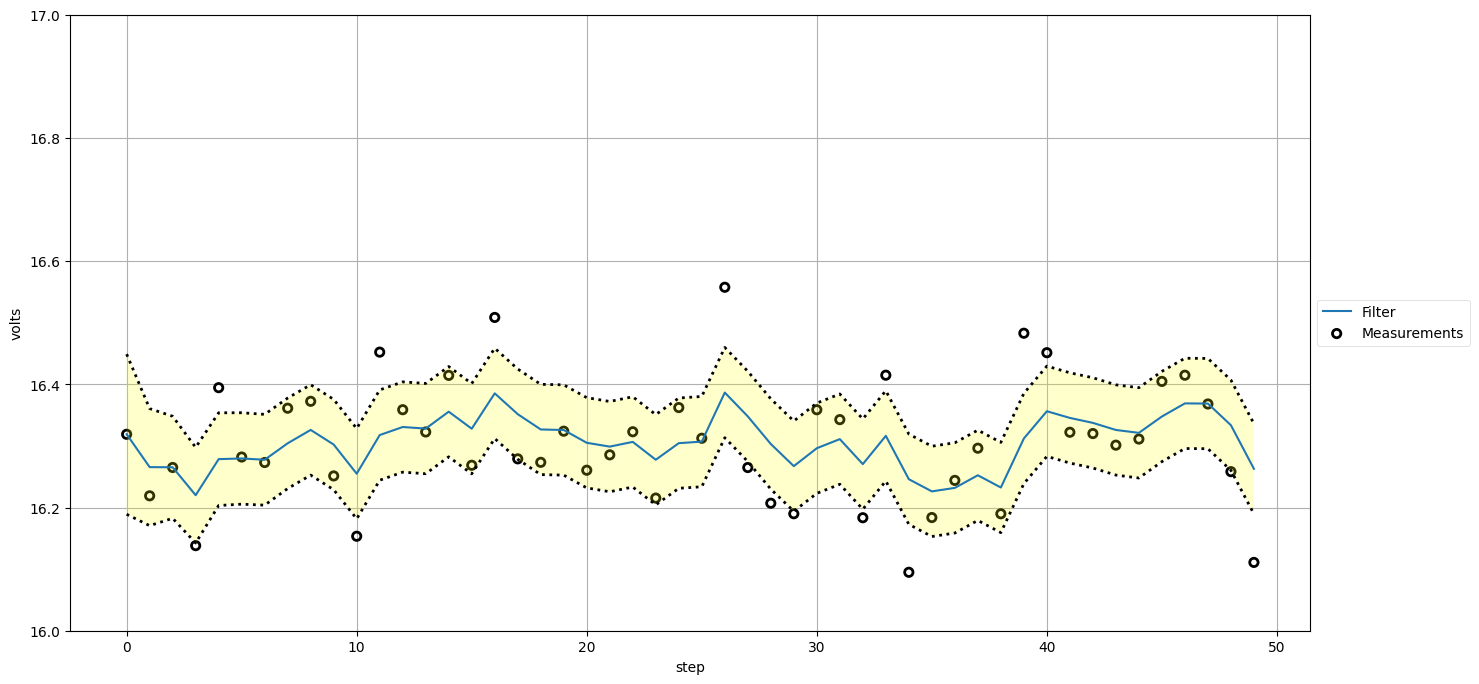

Variance converges to 0.005


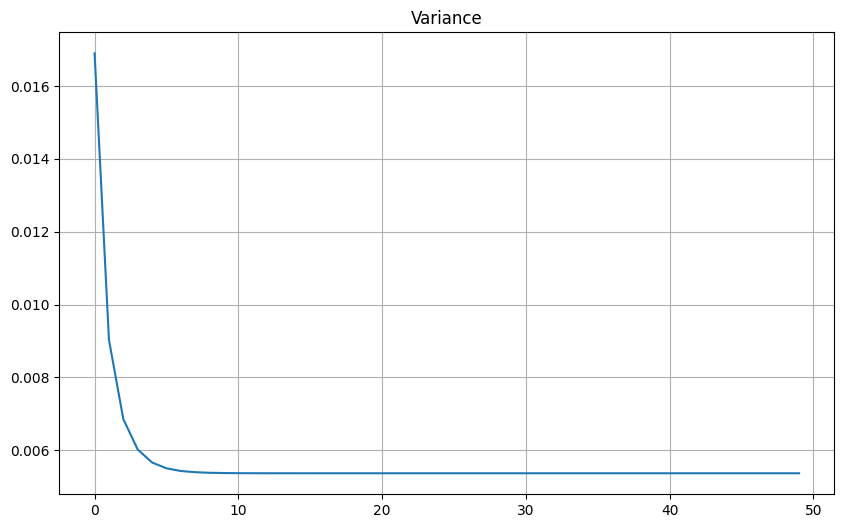

In [23]:
import filterpy.kalman as kf
from numpy.random import randn
import matplotlib.pyplot as plt
import numpy as np 

def plot_measurements(xs, ys=None, dt=None, color='k', lw=1, label='Measurements',
                      lines=False, **kwargs):
    """ Helper function to give a consistant way to display
    measurements in the book.
    """
    if ys is None and dt is not None:
        ys = xs
        xs = np.arange(0, len(ys)*dt, dt)

    plt.figure(figsize=(16,8))
    plt.autoscale(tight=False)
   
    if lines:
        if ys is not None:
            return plt.plot(xs, ys, color=color, lw=lw, ls='--', label=label, **kwargs)
        else:
            return plt.plot(xs, color=color, lw=lw, ls='--', label=label, **kwargs)
    else:
        if ys is not None:
            return plt.scatter(xs, ys, edgecolor=color, facecolor='none',
                        lw=2, label=label, **kwargs),
        else:
            return plt.scatter(range(len(xs)), xs, edgecolor=color, facecolor='none',
                        lw=2, label=label, **kwargs),

def plot_filter(xs, ys=None, dt=None, c='C0', label='Filter', var=None, **kwargs):
    """ plot result of KF with color `c`, optionally displaying the variance
    of `xs`. Returns the list of lines generated by plt.plot()"""

    if ys is None and dt is not None:
        ys = xs
        xs = np.arange(0, len(ys) * dt, dt)
    if ys is None:
        ys = xs
        xs = range(len(ys))

    lines = plt.plot(xs, ys, color=c, label=label, **kwargs)
    if var is None:
        return lines

    var = np.asarray(var)
    std = np.sqrt(var)
    std_top = ys+std
    std_btm = ys-std

    plt.plot(xs, ys+std, linestyle=':', color='k', lw=2)
    plt.plot(xs, ys-std, linestyle=':', color='k', lw=2)
    plt.fill_between(xs, std_btm, std_top,
                     facecolor='yellow', alpha=0.2)

    return lines

def show_legend():
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    
def set_labels(title=None, x=None, y=None):
    """ helps make code in book shorter. Optional set title, xlabel and ylabel
    """
    if x is not None:
        plt.xlabel(x)
    if y is not None:
        plt.ylabel(y)
    if title is not None:
        plt.title(title)    


# Measurements voltage_std = .13

R=0.13**2

voltage_std=.13
actual_voltage=16.3

#Initial state x = gaussian(25., 1000.) 

xhat=25. 
Phat=1000

#process_model = gaussian(0., Q)
u=0
Q=.05**2

## Generate the measurements: 
N = 50
def volt(voltage, std):
    return voltage + (randn() * std)

zs = [volt(actual_voltage, voltage_std) for i in range(N)] #vector of measurements 
ps = []
estimates = []

for z in zs:
    
    xtilde, Ptilde = kf.predict(x=xhat, P=Phat, u=u, Q=Q)
    xhat, Phat     = kf.update(x=xtilde, P=Ptilde, z=z, R=R)

    # save for latter plotting
    estimates.append(xhat)
    ps.append(Phat)
    

# plot the filter output and the variance
plot_measurements(zs)
plot_filter(estimates, var=np.array(ps))
show_legend()
plt.ylim(16, 17)
set_labels(x='step', y='volts')
plt.show()
    
plt.figure(figsize=(10,6))
plt.plot(ps)
plt.title('Variance')
print('Variance converges to {:.3f}'.format(ps[-1]))